# Generate test signals

Build your own stimulus, look at it, and write it out as Q-format files for the VHDL testbenches and the board.

1. **Parameters** - sample rate, length, word format, output folder.
2. **Define signals** - combine the building blocks from `gen_signals.py` (edit freely).
3. **Look at them** - time domain and spectrum.
4. **Quantize and write** - `.txt` (signed decimal, for `textio`) and `.hex` (two's complement, for BRAM init).

Run top to bottom. Only sections 1 and 2 normally need editing.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "../models")
from gen_signals import (sine, add, scale, dc, gaussian_noise, uniform_noise,
                         step, impulse, square, chirp, to_codes, generate, plot)

## 1. Parameters

`INT_BITS` counts the sign bit, so Q2.15 covers -2.0 .. +1.99997 in steps of 2^-15.
Use a different `OUT_DIR` than `../stimulus` (the standard set made by `python3 gen_signals.py`) so you don't overwrite it.

In [2]:
FS        = 1000.0   # sample rate in Hz
N         = 2048     # samples per signal
INT_BITS  = 2        # integer bits, including sign
FRAC_BITS = 15       # fractional bits
SEED      = 1234     # noise seed - same seed gives the same noise every run

OUT_DIR   = "../stimulus_custom"
WRITE     = True     # False = just look, don't write files

## 2. Define signals

Each entry is `name: list of floats`. Amplitudes are real numbers (1.0 = full "one" in Qm.f), so keep the **peak** below `2**(INT_BITS-1)`, otherwise samples saturate (reported in section 4).

Building blocks: `sine(freq, amp)`, `square(freq, amp)`, `chirp(f0, f1, amp)`, `step(amp, start)`, `impulse(amp, at)`, `dc(level)`, `gaussian_noise(sigma)`, `uniform_noise(amp)`, combined with `add(...)` and `scale(x, gain)`. Pass `n=N, fs=FS` so they follow the parameters above.

In [3]:
signals = {
    # same shapes as the standard set, now following FS / N above
    "sine_10hz":         sine(10, 1.0, n=N, fs=FS),
    "compound_10_100hz": add(sine(10, 0.8, n=N, fs=FS), sine(100, 0.5, n=N, fs=FS)),
    "noisy_sine_10hz":   add(sine(10, 0.8, n=N, fs=FS), gaussian_noise(0.2, n=N, seed=SEED)),

    # examples of building your own
    "three_tones":       add(sine(5, 0.5, n=N, fs=FS), sine(50, 0.4, n=N, fs=FS), sine(200, 0.3, n=N, fs=FS)),
    "sine_plus_dc":      add(dc(0.5, n=N), sine(20, 0.6, n=N, fs=FS)),
    "noisy_square_5hz":  add(square(5, 0.6, n=N, fs=FS), uniform_noise(0.15, n=N, seed=SEED)),
}

## 3. Look at them

Time domain first, then the magnitude spectrum - that's where the tones and the noise floor are visible.

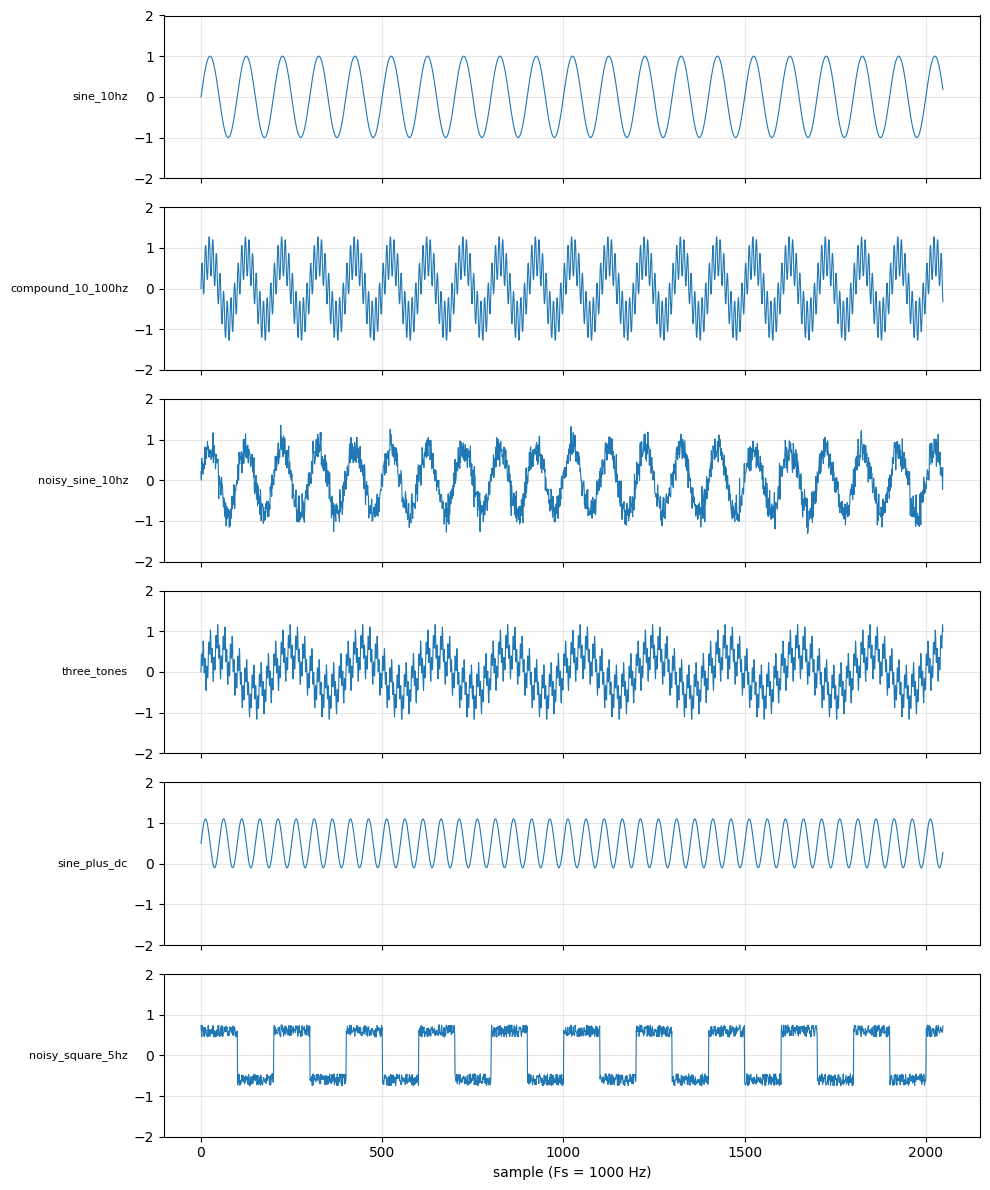

In [4]:
# Quantize in memory only (files are written in section 4), so the plots show exactly what the hardware will see.
codes = {k: to_codes(v, INT_BITS, FRAC_BITS) for k, v in signals.items()}

fig = plot(codes, fs=FS, frac_bits=FRAC_BITS, int_bits=INT_BITS)
plt.show()

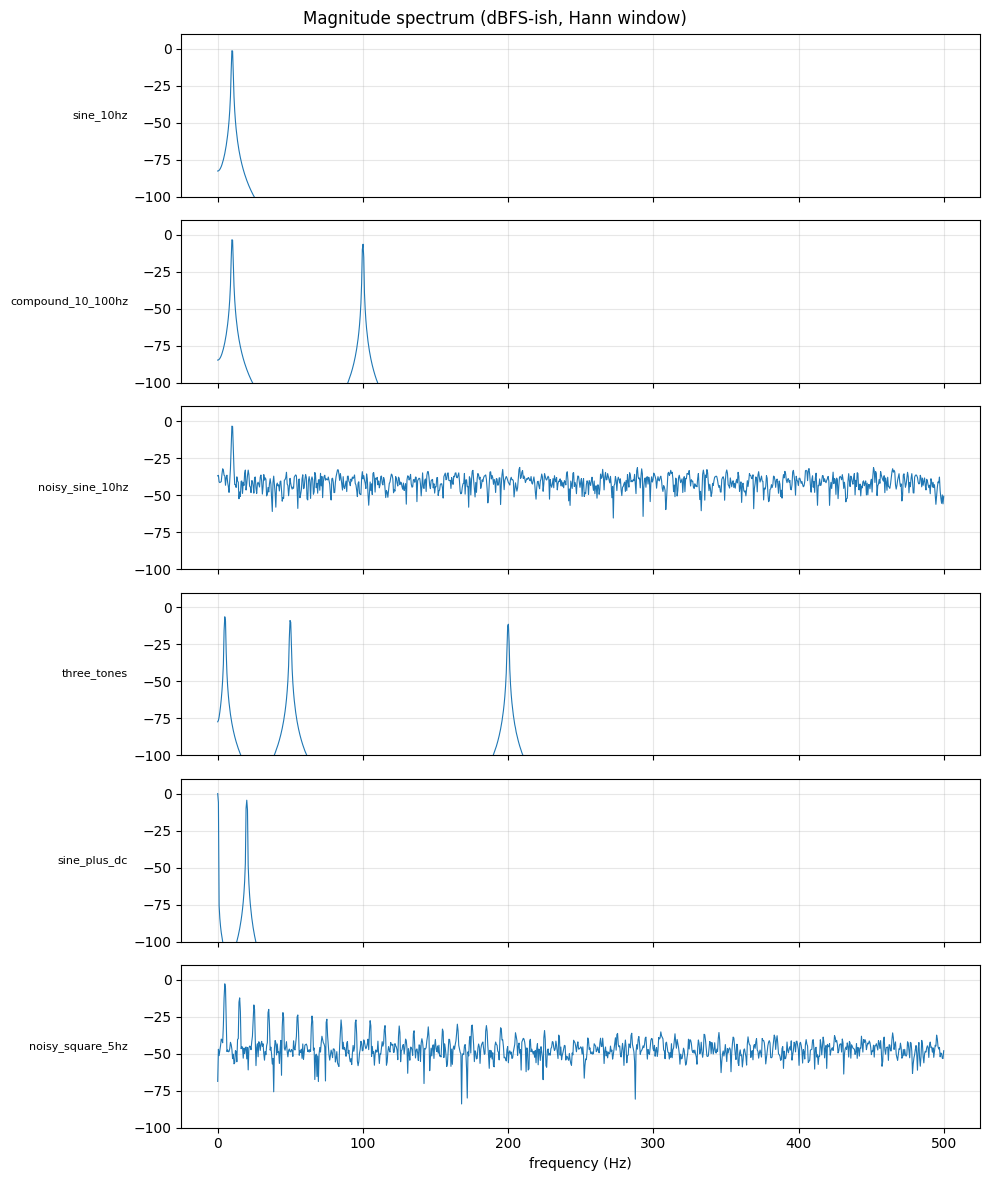

In [5]:
fig, axes = plt.subplots(len(codes), 1, figsize=(10, 2 * len(codes)), sharex=True, squeeze=False)
freqs = np.fft.rfftfreq(N, d=1 / FS)
window = np.hanning(N)
for ax, (name, c) in zip(axes[:, 0], codes.items()):
    x = np.array(c) / 2**FRAC_BITS
    spec = np.abs(np.fft.rfft(x * window)) / (window.sum() / 2)
    ax.plot(freqs, 20 * np.log10(spec + 1e-12), lw=0.8)
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8)
    ax.set_ylim(-100, 10)
    ax.grid(alpha=0.3)
axes[-1, 0].set_xlabel("frequency (Hz)")
fig.suptitle("Magnitude spectrum (dBFS-ish, Hann window)")
fig.tight_layout()
plt.show()

## 4. Quantize and write

Writes `<name>.txt` and `<name>.hex` into `OUT_DIR` and reports min/max codes and any saturated samples.

In [6]:
if WRITE:
    generate(signals, out_dir=OUT_DIR, int_bits=INT_BITS, frac_bits=FRAC_BITS)
    print("written to", os.path.abspath(OUT_DIR))
else:
    print("WRITE is False - nothing written")

sine_10hz            2048 samples, min= -32768 max=  32768
compound_10_100hz    2048 samples, min= -41590 max=  41590
noisy_sine_10hz      2048 samples, min= -42845 max=  44422
three_tones          2048 samples, min= -38070 max=  38070
sine_plus_dc         2048 samples, min=  -3238 max=  36006
noisy_square_5hz     2048 samples, min= -24559 max=  24576
written to C:\Users\scholar\Documents\logic_playground\dsp02_test_signals\stimulus_custom
